# Two shapes at the limit
### Sixteen points in the plane with seven distances: a classification you can run

> **Theorem.** Up to similarity, there are exactly two sets of 16 points in the plane that determine at most seven distinct distances.

*Similarity* means translation, rotation, reflection and scaling. The two sets, $E_1$ and $E_2$, are drawn below. Both are pieces of the triangular lattice, as Erdős and Fishburn conjectured in 1996 for every maximum set with seven or more distances [EF]. Seventeen points always determine at least eight distances [AA], and six distances allow at most 13 points [W], so "at most seven" and "exactly seven" mean the same thing here: these are the two largest seven-distance sets.

The proof is computer-assisted, and this notebook is the proof: the text explains each idea, the code next to it carries it out in exact arithmetic, and the last section lists precisely what is taken from the literature.

In [1]:
import time
from collections import Counter
from fractions import Fraction
from itertools import combinations, product
from pathlib import Path

import sympy as sp
from IPython.display import Code, Markdown, display

import fewdist as fd        # the mathematics (fewdist.py, next to this notebook)
import figures as fg        # drawing helpers (figures.py)

DATA = Path("data")
# True: solve the 228 systems of §4 again instead of loading the saved result (about four minutes)
RECOMPUTE = False
started = time.time()
print("SymPy", sp.__version__)

SymPy 1.14.0


E1: 16 points; squared distance -> number of pairs: {1: 33, 3: 24, 4: 20, 7: 24, 9: 9, 12: 4, 13: 6}
E2: 16 points; squared distance -> number of pairs: {1: 33, 3: 24, 4: 18, 7: 24, 9: 9, 12: 6, 13: 6}


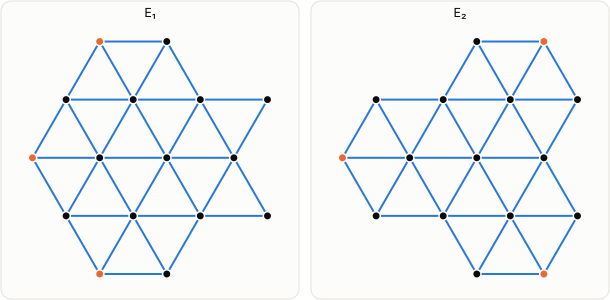

In [2]:
def norm(a, b):
    "Squared length of the lattice vector a + b·ω, where ω = e^{iπ/3}."
    return a*a + a*b + b*b

lattice_d2 = lambda p, q: norm(p[0] - q[0], p[1] - q[1])

star = [(a, b) for a, b in product(range(-2, 3), repeat=2) if norm(a, b) in (0, 1, 3)]   # 13 points
E1 = star + [(-2, 0), (-2, 2), (0, -2)]
E2 = star + [(-2, 0), (0, 2), (2, -2)]

for name, E in (("E1", E1), ("E2", E2)):
    census = Counter(lattice_d2(p, q) for p, q in combinations(E, 2))
    print(f"{name}: {len(E)} points; squared distance -> number of pairs:",
          dict(sorted(census.items())))

orange = {13: fg.ACCENT, 14: fg.ACCENT, 15: fg.ACCENT}
fg.figure([fg.panel(fg.lattice_xy(E), segments="shortest", title=name, box=300, marks=orange)
           for name, E in (("E₁", E1), ("E₂", E2))])

<small>*Segments join points at the shortest distance. The 13 black points are common to both sets; the three orange points differ.*</small>

## The plan

The difficulty is that a set of 16 points has 28 degrees of freedom up to similarity, and "seven distances" does not obviously pin anything down. The proof goes through a much more rigid object, a set of **ten** points with at most **six** distances.

| Step | Statement | Where |
|---|---|---|
| 1 | Every 16-point set with at most seven distances contains ten points with at most six distances: a *core*. | §5 |
| 2 | A core has one of 228 *distance patterns*. | §1, §3 |
| 3 | Each of the 228 patterns is realised by finitely many point sets; all of them are computed exactly. | §2, §4 |
| 4 | Every way of adding six points to a core without exceeding seven distances is found. All results have squared distances proportional to 1, 3, 4, 7, 9, 12, 13. | §6 |
| 5 | Every 16-point set with these squared distances is $E_1$ or $E_2$. | §7 |

§8 checks the computation from the opposite direction, and §9 is the ledger of everything that is assumed.

**Running the notebook.** *Run All* takes about two minutes. One long computation, the exact solution of the 228 systems of equations in §4 (about four minutes on two cores), loads its saved result by default; set `RECOMPUTE = True` in the first code cell to redo it. Requirements: Python 3.10 or later and SymPy.

**The code.** The mathematics lives in `fewdist.py`, about a thousand lines (comments included) organised in the same order as this notebook; `figures.py` only draws. The notebook calls these functions and shows the most important ones in full.

## 1. Distance patterns

### 1.1 From a point set to a coloured graph

Take $n$ points. Each of the $\binom n2$ pairs has a distance. Now forget the numbers and remember only **which pairs are equally far apart**. What is left is a colouring of the edges of the complete graph $K_n$: two edges get the same colour exactly when the two distances are equal. The colours have no names and no order; only the way they split the pairs into classes matters. We call this the **distance pattern** of the point set.

In the code a pattern is a tuple with one colour number per pair, the pairs listed in the order $(0,1),(0,2),\dots,(0,n-1),(1,2),\dots$, and the colours numbered in order of first appearance.

pairs:   ((0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3))
pattern: (0, 0, 0, 0, 0, 1)


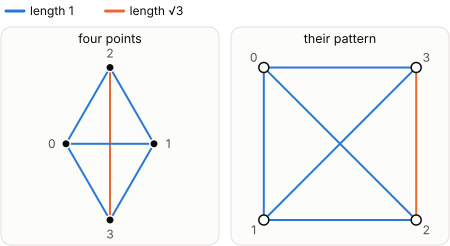

In [3]:
# lattice coordinates: two equilateral triangles glued along a side
rhombus = [(0, 0), (1, 0), (0, 1), (1, -1)]
p = fd.pattern_of(rhombus, lattice_d2)
print("pairs:  ", fd.pairs(4))
print("pattern:", p)

fg.figure([fg.panel(fg.lattice_xy(rhombus), title="four points", labels="0123"),
           fg.abstract_panel(p, 4, title="their pattern", labels="0123")],
          legend_entries=[(0, "length 1"), (1, "length √3")])

<small>*Left: the point set. Right: the same information as a colouring of $K_4$. Here and below, the vertices of a pattern are drawn as empty circles: they are not points of the plane yet, and where they sit in the picture means nothing.*</small>

### 1.2 When are two patterns the same?

Numbering the points differently changes the tuple but not the pattern. Two patterns are **equivalent** if one becomes the other after renumbering the points (colour names never mattered). To compare patterns we compute a **canonical form**: a tuple that is the same for all equivalent patterns and different otherwise.

`fd.canonical` does this by *individualise and refine*, the idea behind the graph-isomorphism program nauty. Sort the points into classes according to what they see (how many edges of each kind, leading to which classes) and repeat until nothing changes. If a class still contains several points, try each of them as "the first" and refine again. Each branch ends with an ordering of the points; the smallest colour tuple over all these orderings is the canonical form. Nothing in the procedure depends on the original numbering.

In [4]:
shuffled = [rhombus[k] for k in (2, 0, 3, 1)]
q = fd.pattern_of(shuffled, lattice_d2)
print("same points, other numbering:", q)
print("canonical forms:", fd.canonical(p), fd.canonical(q), "-> equivalent:", fd.same_pattern(p, q))

same points, other numbering: (0, 1, 0, 0, 0, 0)
canonical forms: (0, 1, 1, 1, 1, 1) (0, 1, 1, 1, 1, 1) -> equivalent: True


### 1.3 How many patterns are there?

For three points there are three: equilateral, isosceles, scalene. For four points we can simply colour the six edges in all $203$ ways (the number of partitions of a six-element set) and keep one representative of each class.

3 points: 3 patterns;  number of colours -> patterns: {1: 1, 2: 1, 3: 1}
4 points: 25 patterns;  number of colours -> patterns: {1: 1, 2: 5, 3: 9, 4: 7, 5: 2, 6: 1}


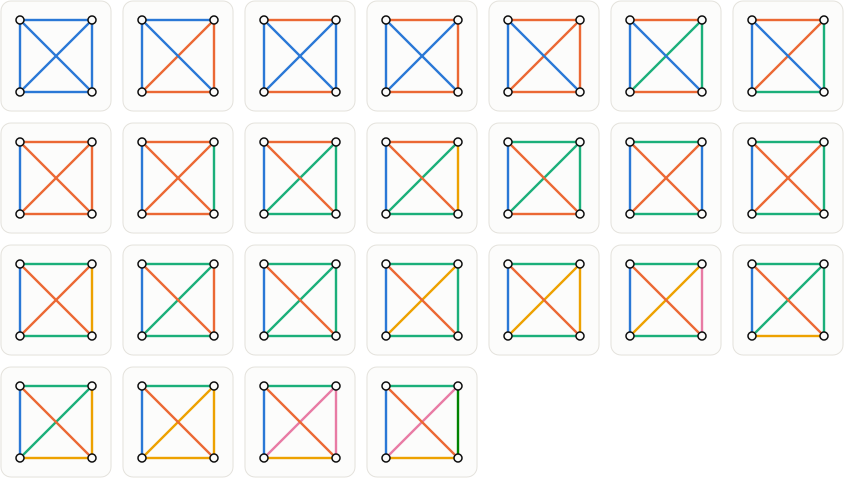

In [5]:
for n in (3, 4):
    pats = fd.all_patterns(n)
    by_colours = dict(sorted(Counter(max(p) + 1 for p in pats).items()))
    print(f"{n} points: {len(pats)} patterns;  number of colours -> patterns: {by_colours}")

four = fd.all_patterns(4)
fg.figure([fg.abstract_panel(p, 4, box=112, margin=20, radius=3.2, width=2.4) for p in four],
          columns=7)

<small>*All 25 patterns on four points. Colours only separate classes; which colour is used for which class is arbitrary.*</small>

The numbers grow quickly. On five points there are already 1205 patterns with at most six colours (six is all we shall need):

In [6]:
t0 = time.time()
n_colourings, five = 0, set()
for c in fd.colourings(10, max_colours=6):       # the 10 pairs of five points, colours unnamed
    n_colourings += 1
    five.add(fd.canonical(c))
print(f"{n_colourings} colourings of K5 with at most six colours make {len(five)} patterns",
      f" ({time.time() - t0:.0f} s)")

109299 colourings of K5 with at most six colours make 1205 patterns  (7 s)


### 1.4 A pattern is not a shape

A pattern is combinatorial; a point set is geometric. Going back from a pattern to point sets, three things can happen.

* **No point set at all.** The one-colour pattern on four points asks for four points that are pairwise equidistant. In the plane there are none.
* **Finitely many shapes.** The pattern of the square (four equal sides, two equal diagonals) is realised only by squares. Such a pattern is called **rigid**. A rigid pattern can have more than one shape; we shall meet one with two in §2.2.
* **Infinitely many shapes.** "Opposite sides equal, diagonals equal" describes all rectangles. Such a pattern is **flexible**.

Here "shape" means a point set up to similarity. The whole proof rests on one fact, established in §3 and §4: *every pattern of ten points with at most six distances is rigid, and there are 228 of them.*

## 2. From a pattern to its shapes

### 2.1 Squared lengths as unknowns

Give each colour an unknown: the **squared** length of its edges (squares, because then everything is polynomial). One colour serves as the unit and gets the value 1; the code uses the colour of the pair $\{0,1\}$. So a pattern with $k$ colours has $k-1$ unknowns $x_1,\dots,x_{k-1}$.

Which values of the unknowns come from actual points in the plane? Put $p_0$ at the origin and let $v_i = p_i - p_0$. Writing $D_{ij}=|p_i-p_j|^2$ and expanding $|v_i-v_j|^2$ gives the dot products in terms of the distances alone:

$$\langle v_i, v_j\rangle = \tfrac12\,\bigl(D_{0i}+D_{0j}-D_{ij}\bigr).$$

The matrix $G=(\langle v_i,v_j\rangle)_{i,j\ge1}$ is the **Gram matrix**. If the points lie in a plane, any three of the vectors $v_i$ are linearly dependent, so **every $3\times3$ minor of $G$ vanishes**. These are polynomial equations in the unknowns. For four points there is exactly one, $\det G=0$; it says that the tetrahedron $p_0p_1p_2p_3$ has volume zero.

Here is the pattern "equilateral triangle $0,1,2$; point 3 as far from 2 as the side of the triangle; point 3 equally far from 0 and 1".

In [7]:
#        pairs: 01 02 03 12 13 23
kite = (0, 0, 1, 0, 1, 0)
xs, values = fd.length_symbols(kite)                 # one unknown x1; colour 0 is the unit
D = sp.Matrix(fd.distance_table(kite, values))
G = sp.Matrix(fd.gram2(fd.distance_table(kite, values))) / 2
display(Markdown("Squared distances $D$, Gram matrix $G$, and $\\det G$:"),
        D, G, sp.factor(G.det()))

Squared distances $D$, Gram matrix $G$, and $\det G$:

Matrix([
[ 0,  1, 1, x1],
[ 1,  0, 1, x1],
[ 1,  1, 0,  1],
[x1, x1, 1,  0]])

Matrix([
[  1,  1/2,  1/2],
[1/2,    1, x1/2],
[1/2, x1/2,   x1]])

-(x1**2 - 4*x1 + 1)/4

So $x_1^2-4x_1+1=0$, that is $x_1 = 2\pm\sqrt3$. Both roots are genuine, and they give two *different* shapes with the same pattern: point 3 lies on the axis of the triangle at distance 1 from the corner 2, on one side of that corner or on the other.

The function `fd.solve_lengths` automates all of this (how is the subject of the next subsections), and `realisation` turns a solution into points.

lengths (unit, x1): (1, t)   where Q(t), t a root of t**2 - 4*t + 1
real roots at which this is a planar point set: [0, 1]


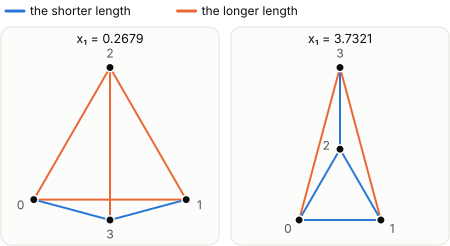

In [8]:
solution, = fd.solve_lengths(kite)
print("lengths (unit, x1):", solution.lengths, "  where", solution.field)
print("real roots at which this is a planar point set:", solution.embeddings)

panels = []
for root in solution.embeddings:
    conf = solution.realisation(root)
    x1 = solution.field.approx(solution.lengths[1], root)
    panels.append(fg.panel(conf.xy(), title=f"x₁ = {x1:.4f}", labels="0123"))
fg.figure(panels, legend_entries=[(0, "the shorter length"), (1, "the longer length")])

<small>*One rigid pattern, two shapes. On the left four pairs are at the longer distance, on the right only two.*</small>

### 2.2 Example: the four-point sets with two distances

There are five patterns with two colours on four points. Solving each one recovers a classical list: the six four-point sets with exactly two distances.

7 solutions


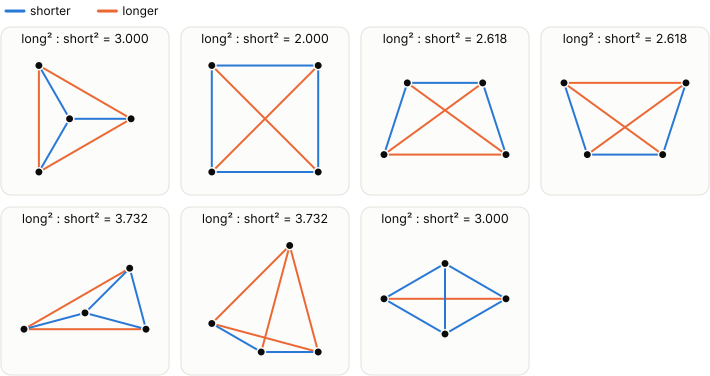

In [9]:
panels = []
for pattern in [p for p in four if max(p) == 1]:
    for sol in fd.solve_lengths(pattern):
        for root in sol.embeddings:
            conf = sol.realisation(root)
            values = [sol.field.approx(v, root) if sol.field else float(v) for v in sol.lengths]
            ratio = max(values) / min(values)
            panels.append(fg.panel(conf.xy(), box=170, margin=24,
                                   title=f"long² : short² = {ratio:.3f}"))
print(len(panels), "solutions")
fg.figure(panels, columns=4, legend_entries=[(0, "shorter"), (1, "longer")])

<small>*Seven solutions, six shapes: the two trapezoids are the same shape (four corners of a regular pentagon) with the points named differently.*</small>

The last remark matters later. *Solutions* are counted for a fixed numbering of the points and a fixed unit colour; *shapes* are counted up to similarity. Renaming points can turn one solution into another without changing the shape.

### 2.3 Solutions that are not point sets

The equations do not know that the points must be distinct, nor that different colours must have different lengths. The square pattern shows the problem in its simplest form.

In [10]:
#          pairs: 01 02 03 12 13 23       (0,1,2,3 in cyclic order; 02 and 13 are the diagonals)
square = (0, 1, 0, 0, 1, 0)
xs, eqs = fd.planarity_equations(square)
print("equation:", sp.factor(eqs[0]), "= 0")

equation: x1**2*(x1 - 2) = 0


The double root $x_1=0$ collapses each diagonal to a point. We want only solutions in which **all lengths are non-zero and pairwise different**. Let $q$ be the product of all the unknowns and all differences of two lengths (here $q=x_1(x_1-1)$). The classical device is to add one more unknown $w$ and the equation $w\,q=1$: a solution with $q=0$ cannot be extended to $w$, and a solution with $q\ne0$ extends in exactly one way. This is known as the Rabinowitsch trick.

In [11]:
x1, w = xs[0], sp.Symbol("w")
sp.groebner([eqs[0], w * x1 * (x1 - 1) - 1], w, x1, order="lex").exprs

[2*w - 1, x1 - 2]

Only $x_1=2$ survives: the diagonal of the unit square. The call to `groebner` is explained next.

### 2.4 Many equations: what a Gröbner basis does for us

With ten points there are $\binom93=84$ equations of the simplest kind (the minors on rows and columns $\{i,j,k\}$, one for each quadruple $0,i,j,k$ of points) in up to five unknowns. We need **all** their solutions, with a guarantee that none is missed. Numerical root-finding cannot give that guarantee; elimination theory can.

A **Gröbner basis** of a system of polynomial equations is another system with exactly the same solutions (over the complex numbers), arranged so that questions about the solutions become mechanical. It plays the role that row-echelon form plays for linear systems, and like row reduction it is computed by exact rational arithmetic. We use three facts.

1. The basis is $\{1\}$ exactly when the system has no solution at all, real or complex.
2. One can read off from the basis whether the number of solutions is finite.
3. If it is finite, a basis for the *lexicographic* ordering is triangular: its last equation involves only the last unknown, the one before only the last two, and so on, so the solutions can be listed by back-substitution, all of them.

`fd.solve_lengths(pattern)` is this recipe: write down the minors, add $w\,q=1$, compute a Gröbner basis, check finiteness, list the solutions. It uses only some of the minors, which is harmless: fewer equations can only produce *more* candidates, and every candidate is tested in §2.6 by actually constructing the points.

### 2.5 Irrational lengths

The lengths are often irrational. Four vertices of a regular pentagon have three sides and three diagonals; the pattern leads to a quadratic equation.

In [12]:
#               pairs: 01 02 03 12 13 23      (0,1,2,3 consecutive vertices: 01, 12, 23 are sides)
trapezoid = (0, 1, 1, 0, 1, 0)
print("equation:", sp.factor(fd.planarity_equations(trapezoid)[1][0]), "= 0\n")
for sol in fd.solve_lengths(trapezoid):
    print("lengths", sol.lengths, "| field:", sol.field, "| valid real roots:", sol.embeddings)

equation: (x1 + 1)*(x1**2 - 3*x1 + 1) = 0

lengths (Fraction(1, 1), Fraction(-1, 1)) | field: None | valid real roots: []
lengths (1, t) | field: Q(t), t a root of t**2 - 3*t + 1 | valid real roots: [0, 1]


There are two things to see.

* The rational solution $x_1=-1$ is discarded (no valid root): a squared length cannot be negative.
* The other solution is written as $x_1=t$ where $t$ is "a root of $t^2-3t+1$", without saying which. Computations with such a number are done with polynomials in $t$, reduced using $t^2=3t-1$. This is exact, and it is how the code represents every irrational length: as an element of a **number field** $\mathbb Q(t)$.

Arithmetic in $\mathbb Q(t)$ decides whether two numbers are *equal*. It cannot decide whether a number is *positive*, because that depends on which root $t$ is: here $t\approx0.38$ or $t\approx2.62$ (the squared golden ratio and its inverse). For signs the code keeps an interval with rational endpoints around each real root and shrinks it until the sign is certain.

In [13]:
K = next(sol.field for sol in fd.solve_lengths(trapezoid) if sol.field)
t = K.t
print("t*t        =", t * t)
print("1/t        =", 1 / t)
print("t + 1/t    =", t + 1 / t, "  (exactly 3)")
for root in range(K.real_roots):
    print(f"at root {root}: t ≈ {K.approx(t, root):.6f},  sign of t - 1:", K.sign(t - 1, root))

t*t        = 3*t - 1
1/t        = 3 - t
t + 1/t    = 3   (exactly 3)
at root 0: t ≈ 0.381966,  sign of t - 1: -1
at root 1: t ≈ 2.618034,  sign of t - 1: 1


> **The conjugation principle.** A computation that uses only $+,-,\times,\div$ and tests of equality gives the same result at every root of the polynomial, because it never asks which root is meant. Only tests of sign distinguish the roots.

We shall use this in §6: the search for extensions of a core uses only equality tests, so it has to be run once per number field, not once per root.

### 2.6 From lengths back to points

A solution of the equations is a list of squared lengths. To see that it is a point set we rebuild the points and check **every** distance. The function is short enough to read in full.

In [14]:
import inspect
show = lambda f: display(Code(inspect.getsource(f), language="python"))
show(fd.place)

def place(pattern, lengths):
    """Rebuild the points from the squared lengths, or return None if they do not fit in a
    plane.  Point 0 is the origin; two other points a, b with independent position vectors
    serve as basis; every point is then found from its dot products with those two; finally
    ALL squared distances are compared with the prescribed ones."""
    n = n_points(pattern)
    D = distance_table(pattern, list(lengths))
    G = [[(D[0][i] + D[0][j] - D[i][j]) / 2 for j in range(n)] for i in range(n)]
    basis = next(((a, b) for a, b in combinations(range(1, n), 2)
                  if G[a][a] * G[b][b] != G[a][b] * G[a][b]), None)
    if basis is None:
        return None                                 # all points on a line
    a, b = basis
    A, B, C = G[a][a], G[b][b], G[a][b]
    H = A * B - C * C
    pts = [((B * G[a][j] - C * G[b][j]) / H, (A * G[b][j] - C * G[a][j]) / H) for j in range(n)]
    conf = Configuration(pts, A, B, C)
    if any(conf.d2(pts[i], pts[j]) != D[i][j] for i, j in pairs(n)):
        return None
    return conf

The coordinates are taken in the basis formed by two of the position vectors, which need not be perpendicular; this keeps all coordinates in the same field as the lengths (no square roots are introduced). The squared length of the vector with coordinates $(x,y)$ is then $Ax^2+2Cxy+By^2$ with $A=\langle e_1,e_1\rangle$, $B=\langle e_2,e_2\rangle$, $C=\langle e_1,e_2\rangle$.

One last condition: the plane must be the Euclidean plane. That is the case when all squared lengths are positive and $AB-C^2>0$ (Cauchy–Schwarz with strict inequality); `LengthSolution.realisation(root)` checks both with certified signs. If $AB-C^2$ were negative the "points" would live in a plane with an indefinite metric, and if the root were not real they would not be real points at all.

**Summary of §2.** For a pattern, `fd.solve_lengths` returns every assignment of non-zero, pairwise different squared lengths satisfying the planarity equations, or reports that there are infinitely many. For each one, `realisation` either returns exact coordinates of a planar point set with exactly that pattern, or `None`.

## 3. Which patterns can occur?

### 3.1 One point at a time

We want all patterns of ten points in the plane with at most six distances. Trying all colourings of the 45 pairs is hopeless. The way through is a simple observation:

> If a pattern is realised by a point set, then each of its sub-patterns (delete some points) is realised too.

So realisable patterns can be built up one point at a time. Suppose we know a list $L_n$ that contains every realisable pattern on $n$ points with at most six colours. Then every realisable pattern on $n+1$ points is found by

1. taking a pattern in $L_n$ and adding a new point, colouring its $n$ new edges in all possible ways (old colours or new ones, at most six in total);
2. keeping only those colourings all of whose $n$-point sub-patterns are in $L_n$;
3. putting the survivors in canonical form and removing duplicates;
4. optionally discarding patterns that are proved unrealisable, to keep the next list short.

This scheme, for exactly this problem, is due to Szöllősi and Östergård [SÖ]. Their test in step 4 is: *is there an assignment of non-zero, pairwise different squared lengths, possibly complex, for which the Gram matrix has rank at most 2?* That is the question of §2.4 with all $3\times3$ minors as equations, answered by fact 1: the pattern is discarded when the Gröbner basis is $\{1\}$. A pattern realised by real points passes, so nothing realisable is ever lost.

### 3.2 The first two levels, live

In [15]:
L4 = [p for p in four if fd.complex_realisable(p)]
print(f"4 points: {len(four)} patterns, {len(L4)} pass the test;",
      "discarded:", [p for p in four if p not in L4])

t0 = time.time()
raw5 = fd.add_a_point(L4, allowed=L4)
print(f"5 points: {len(raw5)} candidates  ({time.time() - t0:.1f} s)")

4 points: 25 patterns, 24 pass the test; discarded: [(0, 0, 0, 0, 0, 0)]


5 points: 1193 candidates  (1.0 s)


At four points only the one-colour pattern is discarded. At five points the candidates are therefore the patterns without a one-coloured $K_4$: 1193 of the 1205 found in §1.3.

Now the test of step 4 on five points. With five or six colours the solution sets are large (five points with six different distances form a two-parameter family) and SymPy's Gröbner bases become slow, so here we run the test on the candidates with at most four colours.

In [16]:
t0 = time.time()
tested = [p for p in raw5 if max(p) + 1 <= 4]
passed = [p for p in tested if fd.complex_realisable(p)]
by_colours = lambda pats: dict(sorted(Counter(max(p) + 1 for p in pats).items()))
print(f"candidates with at most four colours: {len(tested)};  pass: {len(passed)}",
      f" ({time.time() - t0:.0f} s)")
print("number of colours -> candidates:", by_colours(raw5))
print("number of colours -> pass:      ", by_colours(passed))

candidates with at most four colours: 502;  pass: 269  (37 s)
number of colours -> candidates: {2: 13, 3: 120, 4: 369, 5: 442, 6: 249}
number of colours -> pass:       {2: 1, 3: 20, 4: 248}


### 3.3 All the levels

Carried on to ten points, the procedure gives the following table. The first two rows are Table 9 of [SÖ]. They have been reproduced by an independent implementation of the same procedure (`tools/fixed-distances/g7fin/gen` in the `affinemess-applets` repository: canonical forms by nauty, step 4 by Gröbner bases modulo two large primes). The last two rows are that implementation's breakdown by number of colours; for five points and up to four colours it is what the cell above has just recomputed exactly.

In [17]:
import json
summary = json.loads((DATA / "levels_summary.json").read_text())
ns = [str(n) for n in range(4, 11)]

def row(label, value):
    return f"| {label} | " + " | ".join(f"{value(summary[n]):,}" for n in ns) + " |"

display(Markdown("\n".join([
    "| points | " + " | ".join(ns) + " |",
    "|---|" + "---:|" * len(ns),
    row("candidates (steps 1–3)", lambda level: level["raw"]),
    row("pass the test (step 4)", lambda level: level["pruned"]),
    row("… with five colours or fewer",
        lambda level: sum(v for k, v in level["by_colours"].items() if int(k) <= 5)),
    row("… with six colours", lambda level: level["by_colours"].get("6", 0)),
])))

# the part of the table recomputed above
assert (summary["4"]["raw"], summary["4"]["pruned"]) == (len(four), len(L4))
assert summary["5"]["raw"] == len(raw5)
assert all(summary["5"]["by_colours"][str(k)] == by_colours(passed)[k] for k in (2, 3, 4))

| points | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---:|---:|---:|---:|---:|---:|---:|
| candidates (steps 1–3) | 25 | 1,193 | 537,230 | 14,732 | 1,565 | 635 | 228 |
| pass the test (step 4) | 24 | 922 | 20,229 | 4,667 | 1,565 | 635 | 228 |
| … with five colours or fewer | 23 | 678 | 1,620 | 398 | 157 | 57 | 19 |
| … with six colours | 1 | 244 | 18,609 | 4,269 | 1,408 | 578 | 209 |

The shape of the table tells the story. Few points with six colours are almost unconstrained, so the number of patterns explodes at six points. From seven points on the constraints win; by eight points every candidate passes the test, and the lists shrink to 228 patterns at ten points (and on to 62, 15, 3 and 0 at eleven to fourteen points, which is why six distances allow at most 13 points).

### 3.4 The 228 patterns

The file `data/L10.json` contains the 228 patterns of the last column, as produced by the implementation just mentioned. Two quick sanity checks: they are pairwise inequivalent, and each of their nine-point sub-patterns is in the list of 635.

In [18]:
patterns = fd.load_patterns(DATA / "L10.json")
nine = {fd.canonical(p) for p in fd.load_patterns(DATA / "L9.json")}

assert len({fd.canonical(p) for p in patterns}) == len(patterns) == 228
assert all(fd.canonical(fd.subpattern(p, [v for v in range(10) if v != drop])) in nine
           for p in patterns for drop in range(10))
print(len(patterns), "pairwise inequivalent patterns; number of colours -> patterns:",
      dict(sorted(Counter(max(p) + 1 for p in patterns).items())))

228 pairwise inequivalent patterns; number of colours -> patterns: {5: 19, 6: 209}


### 3.5 Why the list is complete

The logic deserves to be spelled out, because this is where the proof touches a computation that the notebook does not repeat.

> **Proposition A.** Every set of ten points in the plane with at most six distances has one of the 228 patterns in `data/L10.json`.

*Proof.* By [SÖ], the patterns of such sets are among 228 candidates (their count for ten points). So there are **at most** 228 such patterns. In §4 we show that each of our 228 pairwise inequivalent patterns **is** the pattern of an actual point set. That makes 228 different realisable patterns, so there is no room for another. $\qquad\blacksquare$

Note what the argument does and does not need. It needs the *number* 228 from [SÖ] as an upper bound, and it needs our own list to be realisable and free of duplicates, both of which are verified here. It does not need the list of [SÖ] itself (which was not published with the paper), nor any trust in how `L10.json` was produced.

## 4. Every ten-point core, exactly

### 4.1 Solving the 228 systems

For each pattern we now find all solutions of its length equations (§2.4). This is the longest computation of the proof, about four minutes on two cores, so its result (the output of `fd.solve_many`) is saved in `data/solutions.json`. The next cell solves six of the patterns again as a spot check and then loads the file; with `RECOMPUTE = True` it solves all 228.

In [19]:
t0 = time.time()
if RECOMPUTE:
    solutions = fd.solve_many(patterns)
    fd.save_solutions(DATA / "solutions.json", solutions)
    print(f"solved all 228 patterns in {time.time() - t0:.0f} s")
else:
    solutions = fd.load_solutions(DATA / "solutions.json", patterns)
    as_text = lambda sols: sorted(repr(s.lengths) for s in sols)
    for i in (0, 12, 13, 62, 142, 200):
        assert as_text(fd.solve_lengths(patterns[i])) == as_text(solutions[i]), i
    print("loaded the saved solutions; six patterns solved again and compared",
          f" ({time.time() - t0:.0f} s)")

loaded the saved solutions; six patterns solved again and compared  (6 s)


Pattern 12 shows why the device of §2.3 is needed. Its equations alone have infinitely many solutions, a whole curve of them on which several lengths are zero. Only after excluding collapsed solutions does a single one remain.

In [20]:
xs, eqs = fd.planarity_equations(patterns[12])
G = sp.groebner(eqs, *xs, order="grevlex", domain=sp.QQ)
print(f"pattern 12: {len(eqs)} equations in {len(xs)} unknowns")
print("finitely many solutions before excluding collapses?", G.is_zero_dimensional)
print("two members of the Gröbner basis:",
      [sp.factor(g) for g in G.exprs if len(sp.Poly(g, *xs).terms()) == 2][:2])
print("solutions with non-zero, pairwise different lengths:",
      [tuple(map(str, s.lengths)) for s in solutions[12]])

pattern 12: 44 equations in 5 unknowns
finitely many solutions before excluding collapses? False
two members of the Gröbner basis: [x1*(13*x1 - 3)/13, x1*(13*x2 - 7)/13]
solutions with non-zero, pairwise different lengths: [('1', '3/13', '7/13', '1/13', '9/13', '4/13')]


### 4.2 Every solution is a point set

Loading a file proves nothing by itself, so the next cell checks the saved solutions directly. For each solution and each root of its number field it requires that the root is real, that all squared lengths are positive and pairwise different, that the points can be rebuilt in a Euclidean plane, and that all 45 distances come out right (this is inside `realisation`, via `place`). This is exact and takes a second.

In [21]:
cores = []                                # (pattern number, solution, root), one per realisation
for i, sols in enumerate(solutions):
    assert sols, f"pattern {i} has no solution"
    for sol in sols:
        degree = sol.field.deg if sol.field else 1
        assert (sol.field.real_roots if sol.field else 1) == degree       # all roots are real
        assert len(set(sol.lengths)) == max(patterns[i]) + 1              # lengths all different
        for root in range(degree):
            conf = sol.realisation(root)                                  # None if not a point set
            assert conf is not None
            assert fd.pattern_of(conf.points, conf.d2) == fd.rename(patterns[i])
            cores.append((i, sol, root))

tally = lambda counter: dict(sorted(counter.items()))
per_pattern = Counter(i for i, _, _ in cores)
degrees = Counter((sol.field.deg if sol.field else 1) for sols in solutions for sol in sols)
print(len(cores), "solutions in all; every one is a planar point set with exactly its pattern")
print("solutions per pattern -> number of patterns:", tally(Counter(per_pattern.values())))
print("degree of the number field -> number of fields:", tally(degrees))

282 solutions in all; every one is a planar point set with exactly its pattern
solutions per pattern -> number of patterns: {1: 199, 2: 20, 3: 1, 4: 3, 5: 2, 6: 3}
degree of the number field -> number of fields: {1: 199, 2: 22, 3: 1, 4: 2, 5: 2, 6: 3}


> **Proposition B.** Each of the 228 patterns is realised in the plane, in only finitely many ways: there are 282 solutions in all (for the fixed numbering of points and unit colour), and every one of them is a genuine planar point set.

The first half is what Proposition A needed. The second half says that every ten-point set with at most six distances is similar to one of 282 explicitly known point sets. (As in §2.2, several solutions can be the same shape.)

Two things are perhaps unexpected. All 228 patterns are rigid, although nothing in §3 required it. And every solution of the equations is real and Euclidean; no candidate had to be thrown away. For 199 patterns the solution is unique and rational. The other 29 have irrational lengths: in $\mathbb Q(\sqrt3)$ or $\mathbb Q(\sqrt5)$ for 21 of them, and in fields of degree 3 to 6 for the remaining eight, among them the fields of the regular 9-, 11- and 13-gons.

### 4.3 Solutions and shapes

As in §2.2, different solutions can be the same shape. Two realisations are similar exactly when, after dividing all lengths by the shortest one, the two tables of distances agree up to renumbering the points. `fd.shape_key` computes a key that decides this: the list of length ratios in increasing order, each identified as a real number independently of how it is written (by its minimal polynomial and the position of the number among that polynomial's real roots), together with the canonical form of the pattern in which every colour is named by the rank of its length.

In [22]:
shapes = {}
for i, sol, root in cores:
    shapes.setdefault(fd.shape_key(sol, root), []).append(i)

assert all(len(set(ids)) == 1 for ids in shapes.values())      # similar sets share their pattern
print(len(shapes), "shapes;  number of distances -> shapes:",
      tally(Counter(max(patterns[ids[0]]) + 1 for ids in shapes.values())))
print("shapes per pattern -> number of patterns:",
      tally(Counter(Counter(ids[0] for ids in shapes.values()).values())))

257 shapes;  number of distances -> shapes: {5: 19, 6: 238}
shapes per pattern -> number of patterns: {1: 214, 2: 9, 4: 2, 5: 1, 6: 2}


> **Corollary.** Up to similarity there are exactly 257 sets of ten points in the plane with at most six distances: 19 with five distances and 238 with six.

Most patterns have a single shape. Fourteen have several; these are patterns with many symmetries, such as ten corners of a regular 13-gon, where the same combinatorial pattern fits chords of different lengths.

### 4.4 A gallery

One realisation of each of the 228 patterns, in the order of the file.

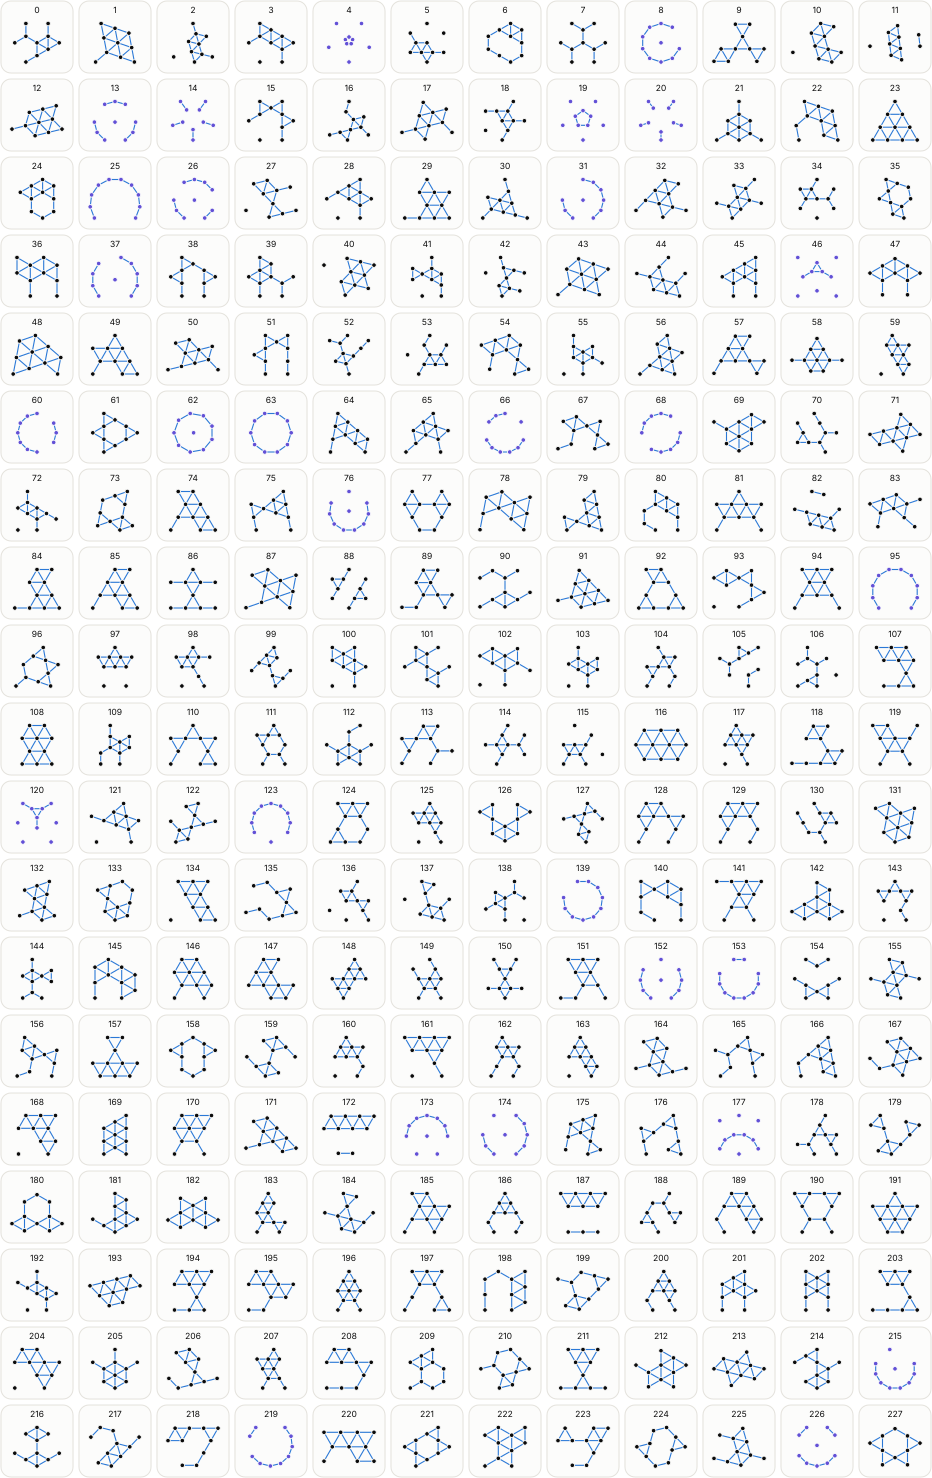

In [23]:
gallery = []
for i, sols in enumerate(solutions):
    sol = sols[0]
    conf = sol.realisation(sol.embeddings[0])
    colour = fg.INK if sol.field is None else fg.EDGE[6]
    gallery.append(fg.panel(conf.xy(), segments="shortest", title=str(i), title_size=8.5,
                            box=74, margin=12, radius=2.3, width=1.1, fill=colour))
fg.figure(gallery, columns=12, gap=4)

<small>*One realisation of each pattern, with its number in the file. Segments join points at the shortest distance. Black: all ratios of squared lengths are rational (199 patterns). Violet: irrational lengths (29 patterns).*</small>

## 5. Ten points are enough

Now the geometric step: why does a 16-point set with seven distances contain a ten-point set with six? The idea goes back to Erdős and Fishburn: **remove points until the largest distance disappears.**

### 5.1 The diameter graph

Let $X$ be a finite set of points in the plane and $D$ its largest distance. Join two points of $X$ when they are at distance $D$. The result is the **diameter graph**; let $X_D$ be the set of points that lie on at least one of its edges, and $m=|X_D|$.

If $I\subseteq X_D$ contains no edge of the diameter graph (an *independent* set), then $A = I\cup(X\setminus X_D)$ contains no pair at distance $D$. So if $X$ has at most seven distances, **$A$ has at most six**, and $|A| = |X| - m + |I|$. We want $|A|\ge 10$, so we need $m$ to be small and $I$ to be large.

The picture shows the diameter graphs of $E_1$ and $E_2$ and, for each, an independent set $I$ (the grey points are the ones removed).

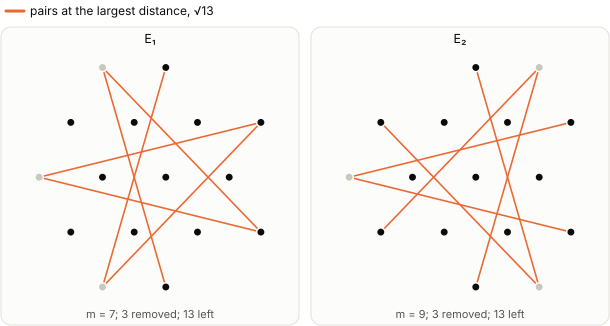

In [24]:
def diameter_graph(points, d2):
    D = max(d2(p, q) for p, q in combinations(points, 2))
    return [(i, j) for i, j in combinations(range(len(points)), 2)
            if d2(points[i], points[j]) == D]

def independent_set(edges):
    "Greedy: keep an endpoint of smallest degree, delete it and its neighbours, repeat."
    nbrs = {}
    for i, j in edges:
        nbrs.setdefault(i, set()).add(j)
        nbrs.setdefault(j, set()).add(i)
    kept = []
    while nbrs:
        v = min(nbrs, key=lambda u: (len(nbrs[u]), u))
        kept.append(v)
        for u in [*nbrs[v], v]:
            for z in nbrs.pop(u):
                if z in nbrs:
                    nbrs[z].discard(u)
    return kept

panels = []
for name, E in (("E₁", E1), ("E₂", E2)):
    edges = diameter_graph(E, lattice_d2)
    ends = sorted({v for e in edges for v in e})
    keep = independent_set(edges)
    removed = [v for v in ends if v not in keep]
    A = [E[v] for v in range(16) if v not in removed]
    assert len({lattice_d2(p, q) for p, q in combinations(A, 2)}) <= 6 and len(A) >= 10
    panels.append(fg.panel(fg.lattice_xy(E), segments=edges, colour_of=lambda i, j: 1,
                           box=300, width=1.6, title=name, marks={v: fg.FAINT for v in removed},
                           subtitle=f"m = {len(ends)};  {len(removed)} removed;  {len(A)} left"))
fg.figure(panels, legend_entries=[(1, "pairs at the largest distance, √13")])

<small>*The diameter graphs of $E_1$ and $E_2$. Removing the grey points leaves no pair at the largest distance.*</small>

### 5.2 Three facts about diameter graphs

These are classical; (i) and (ii) take a few lines each, and (iii) is proved in [W, Lemmas 3–5 and 9].

**(i) Every point of $X_D$ is a corner of the convex hull of $X$.** If $|p-q|=D$, all of $X$ lies in the disc of radius $D$ about $q$ and $p$ is on its boundary circle; a point of a disc that lies on the boundary circle is not between two other points of the disc.

**(ii) Any two edges of the diameter graph meet** (in a common endpoint or in a crossing). If $pq$ and $rs$ were disjoint segments of length $D$, one of the distances between their endpoints would exceed $D$. *(Hopf and Pannwitz, 1934.)*

**(iii) The diameter graph has no cycle of even length and at most one cycle. If it is not a single cycle through all $m$ points of $X_D$, it has an independent set of size at least $\lceil m/2\rceil$.** If it is a single cycle, $m$ is odd and taking every other point gives $(m-1)/2$.

### 5.3 At most 13 points lie on diameters

> **Lemma C** [AA, Lemma 2]. If $X$ has 16 points and at most seven distances, then $m\le13$.

The proof is short, and it uses a classical theorem about convex polygons:

> **Theorem** (Altman 1963; Fishburn 1995). A convex polygon with $h$ corners determines at least $\lfloor h/2\rfloor$ distances. If it determines exactly $\lfloor h/2\rfloor$, it is a regular $h$-gon when $h$ is odd, and a regular $h$-gon or a regular $(h+1)$-gon with one corner removed when $h\ge 8$ is even.

*Proof of Lemma C.* Let $h$ be the number of corners of the convex hull of $X$. By (i), $m\le h$, and by the theorem $\lfloor h/2\rfloor\le7$, so $h\le15$. Suppose $h\ge14$. Then the corners already determine seven distances, so they form a regular 15-gon $R_{15}$, a regular 14-gon $R_{14}$, or $R_{15}$ minus a corner; scale the circumradius to 1. All seven distances of $X$ are chord lengths of this polygon. $X$ has a point $q$ that is not a corner; it lies in the polygon, so $r=|q|<1$.

*$q$ is not the centre:* its distance to the corners would be 1, and a chord $2\sin(\pi j/n)$ equals 1 only if $n=6j$; but $n$ is 14 or 15.

*$q$ is not another point:* a circle about $q$ is not the circumcircle, so it passes through at most two corners. Then the $h$ distances from $q$ to the corners take each value at most twice, hence at least $h/2$ values. For $h=15$ that is eight values, too many. For $h=14$ each of the seven chord lengths occurs exactly twice, so the squared distances from $q$ to the corners add up to twice the sum $S$ of the seven squared chord lengths. On the other hand $\sum_v|q-v|^2=14(1+r^2)-2\,q\cdot\sum_v v$.
For $R_{14}$: $\sum_v v=0$ and $S=16$, so $14(1+r^2)=32$ and $r^2=9/7>1$.
For $R_{15}$ minus the corner $v_0$: $\sum_v v=-v_0$ and $S=15$, so $7r^2+q\cdot v_0=8$; but $q\cdot v_0\le r<1$ gives $7r^2+q\cdot v_0<8$.
Both are impossible, so $h\le13$. $\qquad\blacksquare$

The two sums $S$ follow from $4\sin^2\theta=2-2\cos2\theta$; the next cell confirms them.

In [25]:
import math
for n in (14, 15):
    S = sum((2 * math.sin(math.pi * j / n)) ** 2 for j in range(1, 8))
    print(f"regular {n}-gon, circumradius 1: the seven squared chord lengths add up to {S:.12f}")

regular 14-gon, circumradius 1: the seven squared chord lengths add up to 16.000000000000
regular 15-gon, circumradius 1: the seven squared chord lengths add up to 15.000000000000


### 5.4 The reduction

The last ingredient concerns the one case in which fact (iii) gives a small independent set.

> **Lemma D** [AA, Lemma 4]. Thirteen points whose diameter graph is a single 13-cycle and which determine at most seven distances are the corners of a regular 13-gon.

> **Proposition E.** Every set $X$ of 16 points in the plane with at most seven distances contains ten points with at most six distances.

*Proof.* By Lemma C, $m\le13$.

| case | independent set $I$ | $\lvert A\rvert = 16-m+\lvert I\rvert$ |
|---|---|---|
| diameter graph is not a single cycle through $X_D$ | $\lvert I\rvert\ge\lceil m/2\rceil$ | $\ge 16-\lfloor m/2\rfloor\ge 16-6=10$ |
| a single cycle, $m\le 11$ (then $m$ is odd) | $\lvert I\rvert=(m-1)/2$ | $=16-(m+1)/2\ge 16-6=10$ |
| a single cycle, $m=13$ | — | see below |

In the first two cases $A=I\cup(X\setminus X_D)$ has no pair at the largest distance, hence at most six distances, and at least ten points. In the last case $X_D$ is a 13-point set with at most seven distances whose diameter graph is a 13-cycle, so by Lemma D it is a regular 13-gon. A regular 13-gon has only six distances, so any ten of its corners will do. $\qquad\blacksquare$

We call such a ten-point subset a **core** of $X$. By Propositions A and B, *a core is similar to one of the 282 point sets of §4*. Nothing else about the core will be used; in particular not that it avoids the largest distance.

## 6. Growing a core

Fix one of the 282 point sets as the core $K$, with its set $\Delta$ of five or six squared distances. We look for all ways to add six points so that the 16 points have at most seven distances. At most $b = 7-|\Delta|$ **new** distances may appear in total, so $b$ is 1 or 2; call it the *budget*.

### 6.1 Where can a new point be?

Let $y$ be a point to be added, and look at its ten distances to the points of $K$. At most $b$ different new values occur among them.

* **Some value occurs three times.** Then $y$ is equidistant from three points of $K$, so it is the centre of the circle through them (and they are not collinear).
* **Every value occurs at most twice.** Then at most $2b$ of the ten distances are new, so at least $10-2b$ of them are *old* (they lie in $\Delta$). It will turn out that no core has more than five collinear points, and $10-2b\ge6$; so among the points of $K$ at old distance from $y$ there are three non-collinear ones, $u,v,w$, with squared distances $r,s,t\in\Delta$ to $y$.

In both cases $y$ is determined by three non-collinear points of $K$ and three numbers. Subtracting $|y-u|^2=r$ from $|y-v|^2=s$ cancels the quadratic term and leaves a *linear* equation,

$$2\,\langle y,\,v-u\rangle = |v|^2-|u|^2+r-s,$$

and the same with $w,t$. Two independent linear equations determine $y$. (For the circle centre take $r=s=t$.) So the candidates are:

* the circle centres of all non-collinear triples of $K$, and
* for suitable triples $(u,v,w)$ and all $(r,s,t)\in\Delta^3$, the solution $y$ of the two linear equations.

*Suitable* means: a family of non-collinear triples such that **any** $10-2b$ points of $K$ contain one of them. All 120 triples would do; a handful suffices, and `fd.anchor_triples` chooses them greedily. Each candidate is then tested directly: compute its ten distances to $K$ and keep it if at most $b$ new values occur.

In [26]:
show(fd.candidate_points)

def candidate_points(conf, budget, exhaustive=False):
    """Every point of the plane that can be added to `conf` creating at most `budget` new
    squared distances *to the points of conf*.  Returns {point: set of new distances}.

    Why the list is complete (n = number of points of conf, at most 5 of them collinear is
    checked by anchor_triples):  look at the n distances from a new point y.
      * If some value occurs three times, y is the circumcentre of three points of conf.
      * Otherwise each new value occurs at most twice, so at least n - 2*budget distances
        are old; any n - 2*budget points of conf contain an anchor triple T, and y is
        determined by its (old) distances to T.
    exhaustive=True uses all non-collinear triples instead of the anchor triples (slower;
    the result must be the same, which is a test of the argument)."""
    old = conf.distances()
    lengths = sorted(old, key=repr)
    pts, n = conf.points, len(conf.points)
    seen, good = set(pts), {}
    all_triples = [T for T in combinations(range(n), 3) if not conf.collinear(*(pts[i] for i in T))]
    anchors = all_triples if exhaustive else anchor_triples(conf, n - 2 * budget)

    def consider(y):
        if y in seen:
            return
        seen.add(y)
        new = set()
        for p in pts:
            d = conf.d2(y, p)
            if d not in old:
                new.add(d)
                if len(new) > budget:
                    return
        good[y] = frozenset(new)

    zero = lengths[0] - lengths[0]
    for T in all_triples:                          # circumcentres
        consider(_locate(conf, T, zero, zero, zero))
    for T in anchors:                              # points at old distances from an anchor triple
        for r, s, t in product(lengths, repeat=3):
            consider(_locate(conf, T, r, s, t))
    return good

An example: the first pattern in the list. Its unique realisation has six distances, so the budget is 1.

core 0: 6 distances, budget 1; anchor triples: [(0, 1, 2), (3, 4, 5), (6, 7, 8)]
9 candidate points;  number of added points -> number of ways: {0: 1, 1: 9, 2: 33, 3: 63, 4: 66, 5: 36, 6: 8}


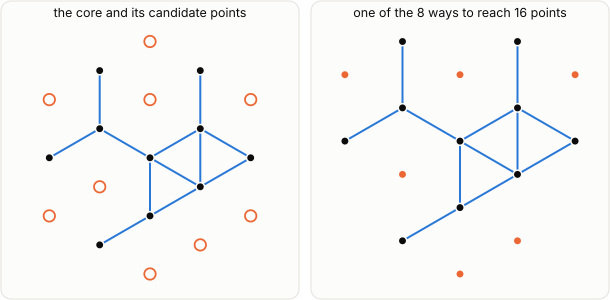

In [27]:
i, sol, root = cores[0]
K0 = sol.realisation(root)
budget = 7 - len(K0.distances())
candidates, subsets = fd.grow(K0, budget)
print(f"core 0: {len(K0.distances())} distances, budget {budget};",
      "anchor triples:", fd.anchor_triples(K0, 10 - 2 * budget))
print(f"{len(candidates)} candidate points;  number of added points -> number of ways:",
      dict(sorted(Counter(map(len, subsets)).items())))
# using all 120 triples instead of the anchor triples gives the same candidates
assert set(candidates) == set(fd.candidate_points(K0, budget, exhaustive=True))

six = [s for s in subsets if len(s) == 6]
rings = [(x, y, "ring") for x, y in K0.xy(candidates)]
dots = [(x, y, "dot") for x, y in K0.xy([candidates[j] for j in six[0]])]
fg.figure([fg.panel(K0.xy(), segments="shortest", box=300, extra=rings,
                    title="the core and its candidate points"),
           fg.panel(K0.xy(), segments="shortest", box=300, extra=dots,
                    title=f"one of the {len(six)} ways to reach 16 points")])

<small>*Black: the ten points of the core. Rings: the only positions where a point can be added. Orange dots: six of them that fit together.*</small>

### 6.2 Which candidates fit together?

Candidates were tested one at a time against the core. A set of candidates must also get along with each other: the distances *between* added points count, and all new values together must stay within the budget. `fd.grow` runs a depth-first search that adds candidates one by one and keeps track of the set of new values; as soon as it has more than $b$ elements, the branch is abandoned (adding more points can only add more values). This enumerates **all** admissible sets of added points, of every size.

### 6.3 All cores

By the conjugation principle of §2.5 the search gives the same result at all roots of a number field, because it only ever asks whether two numbers are equal. So it is run once for each of the 229 solutions-with-field and its result is counted once for each of the real roots. This takes under a minute.

In [28]:
t0 = time.time()
E_PALETTE = [1, 3, 4, 7, 9, 12, 13]
largest, completions, max_collinear, proportional = Counter(), Counter(), 0, set()

for i, sols in enumerate(solutions):
    for sol in sols:
        K = fd.place(sol.pattern, sol.lengths)            # exact coordinates, valid at every root
        on_a_line = max(sum(K.collinear(p, q, r) for r in K.points)
                        for p, q in combinations(K.points, 2))
        max_collinear = max(max_collinear, on_a_line)
        budget = 7 - len(K.distances())
        candidates, subsets = fd.grow(K, budget)          # fails if 10 - 2·budget points are on a line
        n_roots = len(sol.embeddings)
        largest[10 + max(map(len, subsets))] += n_roots
        for s in subsets:
            if len(s) == 6:
                completions[i] += n_roots
                full = K.with_points(candidates[j] for j in s)
                proportional.add(fd.proportional(full.distances(), E_PALETTE))

print(f"all cores extended in {time.time() - t0:.0f} s")
print("at most", max_collinear, "points of a core are collinear")
print("largest number of points reached -> number of cores:", tally(largest))
print(len(completions), "patterns have a core that reaches 16 points;",
      sum(completions.values()), "ways in all")
print("every 16-point result has squared distances proportional to 1, 3, 4, 7, 9, 12, 13:",
      proportional == {True})
assert max(largest) == 16 and sum(largest.values()) == len(cores) and proportional == {True}

all cores extended in 46 s
at most 5 points of a core are collinear
largest number of points reached -> number of cores: {10: 11, 11: 10, 12: 18, 13: 28, 14: 18, 15: 12, 16: 185}
185 patterns have a core that reaches 16 points; 826 ways in all
every 16-point result has squared distances proportional to 1, 3, 4, 7, 9, 12, 13: True


> **Proposition F.** No core can be extended to 17 points with at most seven distances. A core can be extended to 16 points only if it has one of 185 patterns, and then the seven squared distances of the 16-point set are proportional to $1,3,4,7,9,12,13$.

Two remarks. The 826 ways are counted with the core fixed; one 16-point set contains many cores, so this is not a count of shapes. And the first sentence gives the bound $g(7)\le16$ of [AA] again: a 17-point set with at most seven distances would contain a 16-point one, hence a core (Proposition E), and that core would have a seven-point extension.

## 7. Sixteen points with squared distances 1, 3, 4, 7, 9, 12, 13

What remains is a finite problem of a simpler kind: find all 16-point sets whose squared distances all lie in the list $P=\{1,3,4,7,9,12,13\}$ (after scaling). The method of §6.1 works again, with a triangle in place of the core.

Such a set is not collinear (16 points on a line have 15 different distances from an endpoint), so it contains a genuine triangle. Its squared sides $a\le b\le c$ belong to $P$. Place the triangle; every other point of the set has squared distances $(r,s,t)\in P^3$ to its corners, and by the two linear equations of §6.1 that determines the point. So for each of the possible triangles there are at most $7^3$ candidate points, and we need 13 of them that are pairwise at distances in $P$. Each set found is identified by the canonical form of its full table of distances, which decides congruence.

The search knows nothing about lattices.

2 sets up to congruence  (2 s)


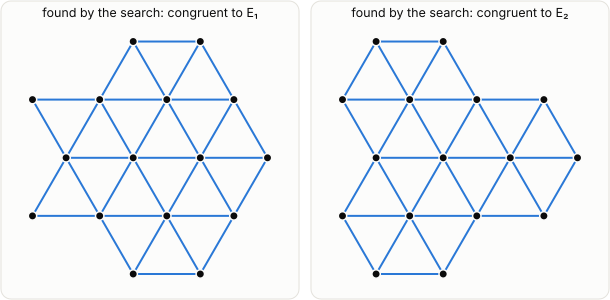

In [29]:
t0 = time.time()
found = fd.sets_with_distances(E_PALETTE, 16)
print(f"{len(found)} sets up to congruence  ({time.time() - t0:.0f} s)")

def lattice_set(E):
    "Lattice points as an exact Configuration: basis 1, ω with <1,1> = <ω,ω> = 1, <1,ω> = 1/2."
    return fd.Configuration([(Fraction(a), Fraction(b)) for a, b in E],
                            Fraction(1), Fraction(1), Fraction(1, 2))

names = {fd.congruence_key(lattice_set(E))[1]: name for name, E in (("E₁", E1), ("E₂", E2))}
assert set(found) == set(names) and len(names) == 2
fg.figure([fg.panel(conf.xy(), segments="shortest", box=300,
                    title=f"found by the search: congruent to {names[key]}")
           for key, conf in sorted(found.items(), key=lambda item: names[item[0]])])

<small>*The two sets as the search produced them, in the coordinates of the triangle it started from.*</small>

$E_1$ and $E_2$ are not similar to each other: they have the same seven distances, but the squared distance 4 occurs 20 times in $E_1$ and 18 times in $E_2$ (first cell). This completes the proof.

> **Theorem.** A set of 16 points in the plane with at most seven distinct distances is similar to $E_1$ or to $E_2$.

*Proof.* Let $X$ be such a set. By Proposition E it contains a core; by Propositions A and B the core is similar to one of the 282 point sets of §4; $X$ is that core with six points added, so by Proposition F its squared distances are proportional to $1,3,4,7,9,12,13$; and by the computation above $X$ is then similar to $E_1$ or $E_2$. $\qquad\blacksquare$

## 8. A check from the other direction

The proof is complete, but a long computation deserves a test that could fail. Here is one that uses none of the machinery of §6.

Take $E_1$ and $E_2$ themselves and list all their ten-point subsets with at most six distances. Each is a core, so its pattern must be among the 228; and the number of ways that core extends to 16 points can be **predicted**: by the theorem every extension is a copy of $E_1$ or $E_2$ around the core, so

$$\#\{\text{extensions of } K\} \;=\; \sum_{k=1,2}\ \frac{\#\{\text{subsets of } E_k \text{ congruent to } K\}\cdot\#\{\text{symmetries of } K\}}{\#\{\text{symmetries of } E_k\}} .$$

If the search of §6 had missed a candidate point or a completion anywhere, or if a pattern were missing from the list, the prediction and the count of §6.3 would disagree.

In [30]:
index = {fd.canonical(p): i for i, p in enumerate(patterns)}

def table_of(points):
    "The squared distances of lattice points, each replaced by its rank among the values."
    values = sorted({lattice_d2(p, q) for p, q in combinations(points, 2)})
    return tuple(values.index(lattice_d2(p, q)) for p, q in combinations(points, 2)), values

classes = {}                  # one entry per shape of ten-point subset with at most six distances
for k, E in enumerate((E1, E2)):
    for S in combinations(E, 10):
        ranks, values = table_of(S)
        if len(values) <= 6:
            ratios = tuple(Fraction(v, values[0]) for v in values)
            key = (ratios, fd.canonical(ranks, named=True))               # decides similarity
            if key not in classes:
                classes[key] = {"count": [0, 0], "pattern": index[fd.canonical(ranks)],
                                "symmetries": fd.symmetry_count(ranks, named=True)}
            classes[key]["count"][k] += 1

symmetries = [fd.symmetry_count(table_of(E)[0], named=True) for E in (E1, E2)]
predicted = Counter()
for c in classes.values():
    predicted[c["pattern"]] += sum(Fraction(c["count"][k] * c["symmetries"], symmetries[k])
                                   for k in (0, 1))

print("symmetries of E1, E2:", symmetries)
print(f"ten-point subsets of E1 or E2 with at most six distances: {len(classes)} shapes,",
      len(predicted), "different patterns")
print("predicted number of extensions, summed over all cores:", sum(predicted.values()))
print("prediction equals the count of §6.3 for every pattern:",
      dict(predicted) == dict(completions))
assert dict(predicted) == dict(completions)

symmetries of E1, E2: [2, 6]
ten-point subsets of E1 or E2 with at most six distances: 185 shapes, 185 different patterns
predicted number of extensions, summed over all cores: 826
prediction equals the count of §6.3 for every pattern: True


The 185 patterns and the 826 extensions of §6.3 are reproduced exactly, pattern by pattern.

## 9. What the proof assumes

Everything in the following list is used without being re-proved in this notebook. Nothing else is.

| | Statement | Source | Used in |
|---|---|---|---|
| 1 | A convex polygon with $h$ corners has at least $\lfloor h/2\rfloor$ distances, and the polygons attaining the bound are as stated in §5.3. | Altman 1963; Fishburn 1995; see [EF, Lemma 2] | Lemma C |
| 2 | Facts (ii) and (iii) on diameter graphs. | Hopf–Pannwitz 1934; [W, Lemmas 3–5, 9] | Proposition E |
| 3 | Lemma D: 13 points with diameter graph $C_{13}$ and at most seven distances form a regular 13-gon. | [AA, Lemma 4]; its proof ends with a computer-checked certificate | Proposition E, last case |
| 4 | The patterns of ten-point planar sets with at most six distances are among 228 candidates. | [SÖ, Table 9]; reproduced, level by level, by an independent implementation of their generation | Proposition A |
| 5 | SymPy's Gröbner-basis routines are correct. | — | §4.1 (that no solution of a pattern is missed) |

Comments.

* **On 4.** Only the number 228 is used, as an upper bound (§3.5). §3.2 recomputes the beginning of the table exactly.
* **On 5.** That the 282 solutions *are* point sets with the right patterns is checked directly in §4.2 and does not depend on SymPy's Gröbner bases. What does depend on them is that there are *no further* solutions. This was cross-checked outside the notebook with a different implementation (FLINT), using the planarity equations of all 210 quadruples of points: the solution sets agree for all 228 patterns.
* **Exact arithmetic.** All computations are in rational numbers or number fields; signs of irrational numbers are certified by interval arithmetic with rational endpoints. No floating-point number takes part in a decision (floating point is used for drawing only).
* **Relation to [AA].** Proposition E reduces to ten-point cores, where [AA] used eleven-point ones, and its last case does not need [AA, Lemma 3]. Proposition F then gives $g(7)\le 16$ once more.
* **Earlier computations.** The classification was first obtained with certified numerical root isolation and 100-digit arithmetic (`tools/fixed-distances/g7count` in the `affinemess-applets` repository), then by an exact computation of which this notebook is a rewrite. All three agree on every count: 228 patterns, 282 solutions, 257 shapes, 185 patterns with extendable cores, 826 extensions, two sets.

### References

* **[AA]** A. Amit and GPT-6 Astra, *The maximum cardinality of a planar seven-distance set*, Hexagon 2610.00534 (2026).
* **[EF]** P. Erdős and P. Fishburn, *Maximum planar sets that determine k distances*, Discrete Mathematics 160 (1996), 115–125.
* **[SÖ]** F. Szöllősi and P. R. J. Östergård, *Constructions of maximum few-distance sets in Euclidean spaces*, Electronic Journal of Combinatorics 27(1) (2020), #P1.23.
* **[W]** X. Wei, *A proof of Erdős–Fishburn's conjecture for g(6) = 13*, Electronic Journal of Combinatorics 19(4) (2012), #P38.
* E. Altman, *On a problem of P. Erdős*, American Mathematical Monthly 70 (1963), 148–157.
* P. Fishburn, *Convex polygons with few intervertex distances*, Computational Geometry 5 (1995), 65–93.

### Words used in this notebook

| word | meaning |
|---|---|
| pattern | a colouring of the pairs of $n$ points, up to renumbering the points and renaming the colours (§1) |
| rigid / flexible | a pattern with finitely / infinitely many shapes (§1.4) |
| solution | an assignment of squared lengths to the colours of a pattern, satisfying the planarity equations, for a fixed numbering and unit (§2) |
| shape | a point set up to similarity |
| core | ten points with at most six distances inside a 16-point set (§5.4) |
| budget | the number of new distances that may still appear when points are added to a core (§6) |

In [31]:
print(f"notebook ran in {time.time() - started:.0f} s")

notebook ran in 110 s
